# Análisis de sentimiento de reseñas — WeLoveReviews

## Objetivo de negocio
La cuenta tiene una puntuación media reportada de **4.5/5**. Antes de entregar un análisis de 500 reseñas, queremos comprobar si la valoración expresada por escrito cuenta una historia compatible con las estrellas, cuantificar reseñas positivas, neutrales y negativas, e identificar dónde una predicción automática podría discrepar.

Este notebook documenta el proceso de principio a fin. En esta primera etapa se examinan la estructura, calidad y composición de los datos, antes de decidir cómo prepararlos para el análisis de sentimiento.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "src":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "reviews.csv"

reviews = pd.read_csv(DATA_PATH)

print(f"Archivo: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Dimensiones: {reviews.shape[0]} filas × {reviews.shape[1]} columnas")
print(f"Columnas: {reviews.columns.tolist()}")
reviews.head()

Archivo: data/raw/reviews.csv
Dimensiones: 500 filas × 3 columnas
Columnas: ['review_id', 'rating', 'review_text']


,review_id,rating,review_text
0,1,5,Visited Harbor House Café last weekend. Great ...
1,2,5,Tried Harbor House Café after seeing it recomm...
2,3,5,Tried Harbor House Café after seeing it recomm...
3,4,5,Visited Harbor House Café last weekend. The st...
4,5,5,Grabbed a quick coffee at Harbor House Café th...


## Integridad y perfil inicial

Comprobamos tipos, campos vacíos, identificadores repetidos y textos idénticos. La duplicación exacta de reseñas merece atención, pero no se eliminará automáticamente: dos clientes pueden escribir el mismo texto, y borrar registros cambiaría la distribución que recibirá el cliente. Primero cuantificamos el fenómeno y preservamos todas las observaciones válidas.

In [2]:
expected_columns = {"review_id", "rating", "review_text"}
assert expected_columns.issubset(reviews.columns), f"Faltan columnas: {expected_columns - set(reviews.columns)}"

integrity = pd.Series(
    {
        "filas": len(reviews),
        "valores_faltantes_total": int(reviews.isna().sum().sum()),
        "review_id_duplicados": int(reviews["review_id"].duplicated().sum()),
        "filas_completas_duplicadas": int(reviews.duplicated().sum()),
        "textos_duplicados_adicionales": int(reviews["review_text"].duplicated().sum()),
        "textos_unicos": int(reviews["review_text"].nunique()),
    },
    name="valor",
)
print(integrity.to_string())
print("\nTipos de datos:")
print(reviews.dtypes.to_string())
print("\nPuntuaciones fuera del rango 1–5:", int((~reviews["rating"].between(1, 5)).sum()))
print("Textos vacíos o solo espacios:", int(reviews["review_text"].astype("string").str.strip().eq("").sum()))

filas                            500
valores_faltantes_total            0
review_id_duplicados               0
filas_completas_duplicadas         0
textos_duplicados_adicionales      7
textos_unicos                    493

Tipos de datos:
review_id      int64
rating         int64
review_text      str

Puntuaciones fuera del rango 1–5: 0
Textos vacíos o solo espacios: 0


## ¿Qué cuentan las puntuaciones?

La distribución de estrellas sirve como referencia explícita para comparar más adelante con la salida del modelo. Una media puede ocultar concentraciones o una minoría importante de experiencias negativas, así que revisamos también los porcentajes y la mediana.

           reseñas  porcentaje
estrellas                     
1               12         2.4
2               18         3.6
3               38         7.6
4               72        14.4
5              360        72.0

Promedio observado: 4.50/5
Mediana observada: 5.0/5


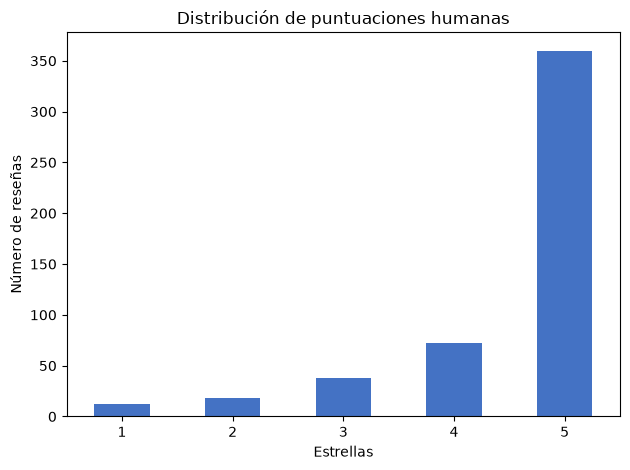

In [3]:
rating_counts = reviews["rating"].value_counts().reindex(range(1, 6), fill_value=0)
rating_summary = pd.DataFrame(
    {
        "reseñas": rating_counts,
        "porcentaje": (rating_counts / len(reviews) * 100).round(1),
    }
)
rating_summary.index.name = "estrellas"
print(rating_summary)
print(f"\nPromedio observado: {reviews['rating'].mean():.2f}/5")
print(f"Mediana observada: {reviews['rating'].median():.1f}/5")

ax = rating_counts.plot(kind="bar", color="#4472C4", rot=0)
ax.set(title="Distribución de puntuaciones humanas", xlabel="Estrellas", ylabel="Número de reseñas")
plt.tight_layout()
plt.show()

La puntuación media observada coincide con el **4.5/5** reportado, pero la distribución no es uniforme: el análisis de texto debe indicar si las reseñas revelan matices que el promedio oculta. La puntuación humana será una referencia para auditar predicciones, no una etiqueta perfecta de lo que expresa el texto.

## Longitud y ejemplos por nivel de estrellas

Revisamos la longitud de los textos y algunas observaciones por puntuación. Las reseñas describen atributos propios de un servicio —comida, personal y ambiente—, un contexto distinto al de reseñas de productos donde se afinó el modelo elegido. Esa diferencia de dominio se tendrá presente al interpretar resultados y falsos negativos.

In [4]:
reviews["text_length"] = reviews["review_text"].str.len()
length_by_rating = reviews.groupby("rating")["text_length"].agg(["mean", "median", "min", "max"]).round(1)
print("Longitud del texto por puntuación:")
display(length_by_rating)

for stars in range(1, 6):
    print(f"\nEjemplo — {stars} estrella(s):")
    print(reviews.loc[reviews["rating"].eq(stars), "review_text"].iloc[0])

Longitud del texto por puntuación:


,mean,median,min,max
rating,,,,
1,175.3,179.5,128,230
2,151.3,156.0,87,175
3,152.7,158.0,86,200
4,182.3,186.0,115,230
5,170.4,172.0,92,227



Ejemplo — 1 estrella(s):
Regular customer at Harbor House Café here. The portions were way too small for the price. Nobody checked on us the entire meal. Not sure I'll be returning.

Ejemplo — 2 estrella(s):
Stopped by Harbor House Café for the first time. My eggs came out cold. The cashier was rude when i asked about the menu. Not sure I'll be returning.

Ejemplo — 3 estrella(s):
Regular customer at Harbor House Café here. Average sandwiches, nothing to write home about. The staff were polite but a bit slow. It's fine for a quick stop.

Ejemplo — 4 estrella(s):
Tried Harbor House Café after seeing it recommended online. Every dish was bursting with flavor. The team clearly cares about the customers. Already planning my next visit.

Ejemplo — 5 estrella(s):
Visited Harbor House Café last weekend. Great spot to work or catch up with friends. Every dish was bursting with flavor. Worth every penny. Already planning my next visit.


## Hallazgos de EDA y propuesta de preparación

- El archivo contiene **500 reseñas** completas, con identificadores únicos y estrellas válidas de 1 a 5; la media y mediana observadas son 4.5 y 5 estrellas, respectivamente.
- La distribución de puntuaciones está inclinada hacia arriba: **72%** tiene 5 estrellas y **86.4%** tiene 4–5; aun así, existe un grupo de puntuación baja que conviene contrastar con el texto.
- Hay **7 textos repetidos** (493 textos únicos). Al no haber duplicados de fila o de ID, se conservarán en el análisis: la unidad de análisis es la reseña recibida, no el texto único.
- La longitud textual es utilizable y los ejemplos muestran aspectos de servicio (personal, tiempos, comida y ambiente). El posible desajuste de dominio se debe tratar como limitación del modelo, no como razón para descartar datos.

**Propuesta de limpieza:** conservar las 500 filas; verificar columnas, valores ausentes, ID y rango de estrellas; recortar solo espacios exteriores si se detectaran, preservando contenido y puntuación. No deduplicar textos ni quitar reseñas negativas. Mantener el original intacto y trabajar con una copia de análisis.

En la siguiente fase se justificará el plan de modelado y se integrará primero el modelo acordado de Hugging Face (`nlptown/bert-base-multilingual-uncased-sentiment`), con la conversión de 1–2 estrellas a negativo, 3 a neutral y 4–5 a positivo. La etiqueta del modelo mide el tono estimado del texto; la estrella humana se usará como señal de contraste, no como verdad absoluta.

## Plan de acción y justificación del modelo

Usaremos el clasificador multilingüe `nlptown/bert-base-multilingual-uncased-sentiment`, entrenado con reseñas de productos, porque fue especificado para este análisis y ya produce una puntuación ordinal de 1 a 5. Fijaremos la revisión del repositorio del modelo para que las predicciones sean reproducibles. Cada reseña conservará la estrella del cliente, las estrellas estimadas y la etiqueta traducida a una banda: 1–2 negativa, 3 neutral y 4–5 positiva.

El modelo se cargará una sola vez y se aplicará a los textos en lotes. Luego compararemos las bandas resultantes tanto con el promedio de negocio (4.5/5) como con las estrellas individuales. El promedio es una referencia agregada, no una etiqueta textual; por eso examinaremos posibles discrepancias y el desajuste entre reseñas de producto y de servicio.

In [5]:
MODEL_ID = "nlptown/bert-base-multilingual-uncased-sentiment"
MODEL_REVISION = "8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d"
BUSINESS_AVERAGE_RATING = 4.5
TEXT_COLUMN = "review_text"

from transformers import pipeline

sentiment_pipeline = pipeline(
    task="sentiment-analysis",
    model=MODEL_ID,
    revision=MODEL_REVISION,
    truncation=True,
)

model_outputs = sentiment_pipeline(reviews[TEXT_COLUMN].tolist(), batch_size=16)

sentiment_results = pd.DataFrame(model_outputs)
sentiment_results["predicted_stars"] = sentiment_results["label"].str.extract(r"(\d+)").astype(int)
sentiment_results["sentiment_band"] = pd.cut(
    sentiment_results["predicted_stars"],
    bins=[0, 2, 3, 5],
    labels=["Negativa", "Neutral", "Positiva"],
    include_lowest=True,
    right=True,
)

scored_reviews = reviews.copy()
scored_reviews["predicted_stars"] = sentiment_results["predicted_stars"].to_numpy()
scored_reviews["sentiment_band"] = sentiment_results["sentiment_band"].astype(str).to_numpy()
scored_reviews["model_confidence"] = sentiment_results["score"].to_numpy()

assert len(scored_reviews) == len(reviews) == 500
assert scored_reviews["predicted_stars"].between(1, 5).all()
scored_reviews.head()

Device set to use cpu


,review_id,rating,review_text,text_length,predicted_stars,sentiment_band,model_confidence
0,1,5,Visited Harbor House Café last weekend. Great ...,172,5,Positiva,0.716958
1,2,5,Tried Harbor House Café after seeing it recomm...,207,5,Positiva,0.982220
2,3,5,Tried Harbor House Café after seeing it recomm...,203,5,Positiva,0.662324
3,4,5,Visited Harbor House Café last weekend. The st...,166,5,Positiva,0.989547
4,5,5,Grabbed a quick coffee at Harbor House Café th...,177,5,Positiva,0.982912


La inferencia asigna a cada reseña una predicción de 1–5 estrellas. El siguiente resumen convierte esa escala a las bandas solicitadas y las compara con la referencia de 4.5 estrellas; la distribución del modelo y la media de ratings contestan preguntas relacionadas, pero no idénticas.

In [6]:
band_order = ["Positiva", "Neutral", "Negativa"]
band_counts = scored_reviews["sentiment_band"].value_counts().reindex(band_order, fill_value=0)
band_summary = pd.DataFrame(
    {
        "reseñas": band_counts,
        "porcentaje": (band_counts / len(scored_reviews) * 100).round(1),
    }
)
band_summary.index.name = "banda de sentimiento"
print("Distribución estimada por el modelo:")
display(band_summary)
print(f"\nPromedio de estrellas humanas: {scored_reviews['rating'].mean():.2f}/5")
print(f"Promedio de estrellas predichas: {scored_reviews['predicted_stars'].mean():.2f}/5")
print(f"Referencia de negocio: {BUSINESS_AVERAGE_RATING:.1f}/5")

comparison = pd.crosstab(
    scored_reviews["rating"], scored_reviews["sentiment_band"], normalize="index"
).reindex(columns=["Negativa", "Neutral", "Positiva"], fill_value=0).mul(100).round(1)
comparison.index.name = "estrellas humanas"
print("\nDistribución de bandas dentro de cada puntuación humana (%):")
display(comparison)

Distribución estimada por el modelo:


,reseñas,porcentaje
banda de sentimiento,,
Positiva,412,82.4
Neutral,41,8.2
Negativa,47,9.4



Promedio de estrellas humanas: 4.50/5
Promedio de estrellas predichas: 4.40/5
Referencia de negocio: 4.5/5

Distribución de bandas dentro de cada puntuación humana (%):


sentiment_band,Negativa,Neutral,Positiva
estrellas humanas,,,
1,100.0,0.0,0.0
2,88.9,11.1,0.0
3,7.9,92.1,0.0
4,1.4,4.2,94.4
5,4.2,0.3,95.6


### Lectura preliminar de resultados

El modelo clasifica **82.4% (412)** de las reseñas como positivas, **8.2% (41)** como neutrales y **9.4% (47)** como negativas. Su promedio de estrellas estimado es **4.40/5**, cercano pero por debajo del promedio humano y de negocio de **4.50/5** (diferencia de 0.10 estrellas). En general la distribución es compatible con una experiencia mayoritariamente positiva, aunque el modelo señala una fracción negativa que el promedio agregado por sí solo no muestra.

La tabla por estrellas revela un patrón claro: 92.1% de las reseñas de 3 estrellas se consideran neutrales y la gran mayoría de las de 4–5 estrellas positivas. Sin embargo, hay **16 casos** con 4–5 estrellas y predicción de 1–2 estrellas (incluidos textos de 5 estrellas con lenguaje claramente elogioso). Estos son candidatos relevantes para la revisión manual y pueden reflejar limitaciones del modelo o su desajuste con el dominio; todavía no se consideran errores confirmados.

El promedio y la tabla cruzada permiten localizar puntuaciones bajas del modelo frente a 4–5 estrellas humanas. Son **candidatos a falsos negativos**, no errores confirmados: las estrellas de cliente no siempre expresan con precisión la polaridad del texto y las predicciones necesitan revisión humana. La fase de auditoría seleccionará ejemplos y buscará patrones de servicio que expliquen desacuerdos.

In [7]:
false_negative_candidates = scored_reviews.loc[
    scored_reviews["predicted_stars"].le(2) & scored_reviews["rating"].ge(4),
    ["review_id", "rating", "predicted_stars", "sentiment_band", "model_confidence", "review_text"],
].sort_values(["rating", "model_confidence"], ascending=[False, True])
print(f"Candidatos a falso negativo (modelo 1–2 estrellas y cliente 4–5): {len(false_negative_candidates)}")
display(false_negative_candidates.head(15))

Candidatos a falso negativo (modelo 1–2 estrellas y cliente 4–5): 16


,review_id,rating,predicted_stars,sentiment_band,model_confidence,review_text
72,73,5,1,Negativa,0.267875,Stopped by Harbor House Café for the first tim...
137,138,5,2,Negativa,0.275116,Tried Harbor House Café after seeing it recomm...
331,332,5,1,Negativa,0.314364,Stopped by Harbor House Café for the first tim...
439,440,5,2,Negativa,0.324101,Regular customer at Harbor House Café here. Ev...
86,87,5,1,Negativa,0.324705,Tried Harbor House Café after seeing it recomm...
488,489,5,1,Negativa,0.333106,Tried Harbor House Café after seeing it recomm...
203,204,5,1,Negativa,0.349168,Came to Harbor House Café for a birthday brunc...
461,462,5,2,Negativa,0.351843,Tried Harbor House Café after seeing it recomm...
253,254,5,1,Negativa,0.364092,Stopped by Harbor House Café for the first tim...
199,200,5,2,Negativa,0.368520,Stopped by Harbor House Café for the first tim...


## Auditoría manual de una muestra de 20 reseñas

La muestra incluye los **16 casos con puntuación humana de 4–5 y predicción de 1–2**, además de cuatro ejemplos de comparación (neutralidad coherente, negatividad coherente y positividad coherente). Se inspeccionaron las reseñas completas, no solo el nivel de estrellas. En la tabla, “coherencia manual” compara la banda predicha con el tono aparente del texto; una puntuación alta del cliente por sí sola no define el sentimiento textual.

| ID reseña | Estrellas humanas | Estrellas modelo | Lectura manual del texto | Evaluación |
|---:|---:|---:|---|---|
| 14 | 4 | 1 | Elogia los platos, al equipo y planea volver. | Falso negativo claro |
| 73 | 5 | 1 | Servicio rápido y amable, comida excelente, buena relación calidad-precio y deseo de volver. | Falso negativo claro |
| 138 | 5 | 2 | Acomodaron una alergia; ambiente acogedor y cálido. | Falso negativo claro |
| 332 | 5 | 1 | Adaptación a una alergia y café perfectamente preparado. | Falso negativo claro |
| 440 | 5 | 2 | Comida muy sabrosa, servidor recuerda al cliente y precio razonable. | Falso negativo claro |
| 87 | 5 | 1 | Menú estacional elogiado, atención a alergia y voluntad explícita de volver. | Falso negativo claro |
| 489 | 5 | 1 | Elogio de comida y equipo; considera que vale cada centavo y planea regresar. | Falso negativo claro |
| 204 | 5 | 1 | Comida excelente; reconoce una interacción grosera, pero dice que la comida lo compensó. | Falso negativo probable; mezcla de polaridad |
| 462 | 5 | 2 | Elogia al equipo y la comida, con intención de regresar. | Falso negativo claro |
| 254 | 5 | 1 | Atención a alergia y lugar agradable; afirma que volverá. | Falso negativo claro |
| 200 | 5 | 2 | Elogia ambiente, música, decoración y comida. | Falso negativo claro |
| 15 | 5 | 1 | Comida sabrosa, ambiente acogedor y deseo de volver. | Falso negativo claro |
| 270 | 5 | 1 | Servidor recuerda al cliente, buena comida y valor; volverá. | Falso negativo claro |
| 409 | 5 | 1 | Comida excelente y servicio rápido y amable. | Falso negativo claro |
| 474 | 5 | 1 | Comida excelente, servicio rápido y lugar favorito. | Falso negativo claro |
| 322 | 5 | 1 | Comida excelente, pero el personal parecía molesto; la comida compensó. | Falso negativo probable; mezcla de polaridad |
| 9 | 3 | 3 | Comida promedio, personal amable aunque lento; experiencia aceptable. | Neutral coherente |
| 16 | 3 | 3 | Menú repetitivo e interacción grosera, pero consideraría volver. | Neutral plausible; texto mixto |
| 32 | 2 | 1 | Huevos fríos, cajero grosero y duda de regresar. | Negativo coherente |
| 1 | 5 | 5 | Comida y ambiente elogiados, buen valor e intención de volver. | Positivo coherente |

En esta muestra, **14 de los 16 desacuerdos** parecen falsos negativos claros; dos son reseñas mixtas donde el modelo podría estar reaccionando a una frase negativa pese a que el autor asignó 5 estrellas y expresa que la experiencia se compensó. La inspección es diagnóstica, no una estimación insesgada de tasa de error, porque se sobrerrepresentaron deliberadamente los casos discordantes.

## Conclusiones preliminares para la account manager

La mayoría de las reseñas se lee positiva según el modelo: aproximadamente **4 de cada 5**; una de cada diez se clasifica negativa y una fracción similar neutral. Esto es coherente en términos generales con una media alta de **4.5/5**, aunque el promedio estimado por el modelo (**4.40/5**) queda ligeramente por debajo.

La advertencia principal es de fiabilidad: el modelo marca como negativas algunas reseñas de 5 estrellas que al leerlas son inequívocamente favorables. En la muestra dirigida, 14 de 16 candidatos parecen falsos negativos claros y dos son casos mixtos. La account manager puede comunicar el panorama como mayoritariamente positivo, pero debería tratar el 9.4% negativo del modelo como una señal para revisar, no como una medición definitiva: el ajuste a reseñas de productos parece penalizar texto de servicios y frases locales mixtas. Conviene acompañar la distribución con ejemplos y validación humana antes de presentarla como conclusión sobre la experiencia del cliente.

## Fase final: auditoría contra los criterios de evaluación

| Criterio | Estado | Evidencia / observación |
|---|---|---|
| Notebook ejecutado con arco objetivos → EDA → limpieza → modelo → resultados → conclusiones | ✅ Cumplido | Celdas con salidas ejecutadas; el relato presenta los datos, la propuesta de limpieza, inferencia, revisión manual y takeaway. |
| Markdown transicional entre bloques importantes | ✅ Cumplido | Secciones breves contextualizan el perfilado, las puntuaciones, la inferencia y la lectura de errores. |
| Integración con `pipeline()` / `from_pretrained()` y sin pesos en el repositorio | ✅ Cumplido | Se utiliza `pipeline()`; no hay archivos de pesos versionados ni almacenados en `models/`. |
| Procesamiento de 500 reseñas | ✅ Cumplido | El CSV de producción conserva los 500 IDs y cada fila tiene predicción y banda. |
| Modelo/revisión fijados | ✅ Cumplido | `nlptown/bert-base-multilingual-uncased-sentiment`, revisión `8f6f4e3a8f70be4b65d3a4a8762b6d781cda240d`. |
| Modelo cargado una vez y reutilizado | ✅ Cumplido | Se crea un solo pipeline fuera de cualquier loop por reseña; la inferencia procesa los textos en lote. |
| Distribución comparada con el promedio de 4.5 | ✅ Cumplido | 82.4% positiva, 8.2% neutral, 9.4% negativa; promedio estimado 4.40 vs. 4.50 humano/negocio. |
| Verificación manual con ejemplos y notas | ✅ Cumplido | Tabla de 20 reseñas con estrellas humanas y predichas, lectura textual y juicio de coherencia. |
| Falsos negativos identificados y explicados | ✅ Cumplido | 16 candidatos con estrellas humanas 4–5/modelo 1–2; 14 parecen falsos negativos claros y dos tienen texto mixto. Se discute el desajuste producto/servicio. |
| `src/app.py` produce el CSV requerido | ✅ Cumplido | Ejecución validada; escribe `data/processed/reviews_with_sentiment.csv` con 500 filas y seis columnas. |
| Dependencias fijadas en `requirements.txt` | ⚠️ Parcial | `transformers==4.52.4` y `torch==2.7.1` están fijadas; varias dependencias heredadas de la plantilla mantienen rangos `>=` o no tienen versión. Si el criterio exige fijar absolutamente todo el entorno, faltaría congelar esas dependencias también. |

**Resultado de auditoría:** los criterios funcionales y analíticos específicos del ejercicio se cumplen. La única salvedad es la fijación integral de todas las dependencias heredadas; las dependencias esenciales para la inferencia sí tienen versiones exactas. El análisis de sentimiento es una segunda opinión automatizada y los candidatos a error deben leerse con el contexto de dominio y la validación humana.

## Extensión opcional: comparación con un modelo alternativo

Para comprobar si cambia la tasa de candidatos a falso negativo, evaluamos `tabularisai/multilingual-sentiment-analysis` sobre las mismas 500 reseñas, en el mismo orden. Contamos como candidatos las reseñas con 4–5 estrellas humanas clasificadas como negativas; las estrellas son una señal para auditar, no una verdad perfecta sobre el tono del texto. Se fija una revisión inmutable del modelo para hacer reproducible esta prueba.

In [8]:
ALT_MODEL_ID = "tabularisai/multilingual-sentiment-analysis"
ALT_MODEL_REVISION = "eea032081f8d247b4303ef3565e7cec1b6f201c9"

alternative_pipeline = pipeline(
    task="text-classification",
    model=ALT_MODEL_ID,
    revision=ALT_MODEL_REVISION,
    truncation=True,
)
alternative_outputs = alternative_pipeline(reviews[TEXT_COLUMN].tolist(), batch_size=16)

alternative_results = pd.DataFrame(alternative_outputs)
alternative_scored = reviews[["review_id", "rating", TEXT_COLUMN]].copy()
alternative_scored["alternative_label"] = alternative_results["label"]
alternative_scored["alternative_confidence"] = alternative_results["score"]
alternative_scored["alternative_band"] = alternative_scored["alternative_label"].replace(
    {
        "Very Negative": "Negativa",
        "Negative": "Negativa",
        "Neutral": "Neutral",
        "Positive": "Positiva",
        "Very Positive": "Positiva",
    }
)

assert len(alternative_scored) == len(reviews) == 500
assert alternative_scored["alternative_band"].notna().all()

alternative_distribution = alternative_scored["alternative_label"].value_counts().reindex(
    ["Very Positive", "Positive", "Neutral", "Negative", "Very Negative"], fill_value=0
)
display(alternative_distribution.to_frame("reseñas"))
print("Bandas agregadas:")
display(alternative_scored["alternative_band"].value_counts().reindex(band_order, fill_value=0).to_frame("reseñas"))

Device set to use cpu


,reseñas
alternative_label,
Very Positive,22
Positive,422
Neutral,11
Negative,44
Very Negative,1


Bandas agregadas:


,reseñas
alternative_band,
Positiva,444
Neutral,11
Negativa,45


In [9]:
alternative_scored["false_negative_candidate"] = (
    alternative_scored["rating"].ge(4)
    & alternative_scored["alternative_label"].isin(["Negative", "Very Negative"])
)
original_fn_ids = set(false_negative_candidates["review_id"])
alternative_fn_ids = set(
    alternative_scored.loc[alternative_scored["false_negative_candidate"], "review_id"]
)
resolved_ids = original_fn_ids - alternative_fn_ids
persistent_ids = original_fn_ids & alternative_fn_ids
new_candidate_ids = alternative_fn_ids - original_fn_ids

comparison_summary = pd.DataFrame(
    {
        "Candidatos FN (4–5 estrellas, predicción negativa)": [len(original_fn_ids), len(alternative_fn_ids)],
        "Tasa sobre reseñas con 4–5 estrellas (%)": [
            round(100 * len(original_fn_ids) / reviews["rating"].ge(4).sum(), 2),
            round(100 * len(alternative_fn_ids) / reviews["rating"].ge(4).sum(), 2),
        ],
    },
    index=["nlptown (modelo original)", "tabularisai (alternativo)"],
)
print("Comparación pareada; mismos 500 textos y mismo criterio de candidato:")
display(comparison_summary)
print(
    f"Reducción de candidatos: {len(original_fn_ids) - len(alternative_fn_ids)} "
    f"({100 * (len(original_fn_ids) - len(alternative_fn_ids)) / len(original_fn_ids):.1f}% frente al original)."
)
print(
    f"Resueltos por el alternativo: {len(resolved_ids)}; persisten de los originales: {len(persistent_ids)}; "
    f"nuevos candidatos del alternativo: {len(new_candidate_ids)}."
)

remaining_fn = alternative_scored.loc[
    alternative_scored["false_negative_candidate"],
    ["review_id", "rating", "alternative_label", "alternative_confidence", TEXT_COLUMN],
].sort_values("review_id")
print("\nTodos los candidatos restantes del modelo alternativo:")
display(remaining_fn)

resolved_from_original = alternative_scored.loc[
    alternative_scored["review_id"].isin(resolved_ids),
    ["review_id", "rating", "alternative_label", "alternative_confidence"],
].sort_values("review_id")
print("\nCandidatos originales que el alternativo ya no clasifica como negativos:")
display(resolved_from_original)

Comparación pareada; mismos 500 textos y mismo criterio de candidato:


,"Candidatos FN (4–5 estrellas, predicción negativa)",Tasa sobre reseñas con 4–5 estrellas (%)
nlptown (modelo original),16,3.70
tabularisai (alternativo),7,1.62


Reducción de candidatos: 9 (56.2% frente al original).
Resueltos por el alternativo: 15; persisten de los originales: 1; nuevos candidatos del alternativo: 6.

Todos los candidatos restantes del modelo alternativo:


,review_id,rating,alternative_label,alternative_confidence,review_text
138,139,5,Negative,0.499376,Tried Harbor House Café after seeing it recomm...
219,220,5,Negative,0.473122,Visited Harbor House Café last weekend. They w...
230,231,5,Negative,0.466236,They went out of their way to accommodate my a...
253,254,5,Negative,0.609048,Stopped by Harbor House Café for the first tim...
289,290,5,Negative,0.400120,Grabbed a quick coffee at Harbor House Café th...
351,352,5,Very Negative,0.474012,They went out of their way to accommodate my a...
414,415,5,Negative,0.379585,Came to Harbor House Café for a birthday brunc...



Candidatos originales que el alternativo ya no clasifica como negativos:


,review_id,rating,alternative_label,alternative_confidence
13,14,4,Positive,0.761169
14,15,5,Positive,0.838223
72,73,5,Positive,0.801790
86,87,5,Positive,0.655486
137,138,5,Positive,0.822697
199,200,5,Positive,0.548940
203,204,5,Positive,0.532519
269,270,5,Positive,0.671609
321,322,5,Positive,0.639236
331,332,5,Positive,0.503257



### Lectura y recomendación para Harbor House Café

En estos datos, el modelo alternativo reduce los candidatos a falso negativo de **16/432 (3.7%)** a **7/432 (1.6%)**, una disminución de **9 casos (56.2%)**. De los 16 candidatos originales, **15** dejan de salir negativos con el modelo alternativo y **uno persiste**. Los siete casos que el alternativo marca como negativos son los IDs **139, 220, 231, 254, 290, 352 y 415**; todos tienen 5 estrellas e incluyen frases sobre la adaptación de alergias. El caso 352 es `Very Negative`, los otros seis `Negative`. Esto sugiere sensibilidad residual a expresiones sobre alergias/atención, aun en reseñas globalmente elogiosas. Además, el alternativo introduce **seis** candidatos de 4–5 estrellas que no estaban entre los 16 del modelo original.

**Recomendación:** preferiría `tabularisai/multilingual-sentiment-analysis` como candidato a una prueba piloto frente a `nlptown`: resuelve la mayoría de los casos discordantes revisados manualmente. No recomendaría sustituirlo de inmediato en producción basándose solo en estas 500 filas: son de un único negocio, las estrellas no son etiquetas perfectas y persisten siete discrepancias, además de seis nuevos candidatos. Antes del cambio, validaría ambos modelos sobre una muestra representativa anotada por personas (incluyendo reseñas mixtas y menciones de alergias), mediría precisión/recall por banda y acordaría umbrales de confianza y revisión humana. Para despliegue se debe fijar la revisión evaluada (`eea032081f8d247b4303ef3565e7cec1b6f201c9`) y monitorear errores por tema. Esta conclusión es exploratoria, no una estimación de rendimiento general.